# Experiment No. 9 (Computer Laboratory – I BE AI&DS)

**Aim:** Data Wrangling  
**Problem Statement:** Data Wrangling on Real Estate Market  
**Dataset:** `"RealEstate_Prices.csv"`  

**Tasks to Perform:**
1. Import the "RealEstate_Prices.csv" dataset. Clean column names by removing spaces, special characters, or renaming them for clarity.
2. Handle missing values in the dataset, deciding on an appropriate strategy (imputation or removal).
3. Perform data merging with additional dataset containing neighborhood demographics.
4. Filter and subset the data based on specific criteria (time period, property type, location).
5. Handle categorical variables by encoding them appropriately (Label Encoding and One-Hot Encoding).
6. Aggregate the data to calculate summary statistics and derived metrics (Price per Square Foot, average sale prices by neighborhood/property type).
7. Identify and handle outliers or extreme values in the data.

In [1]:
# Cell 1 - Import Required Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Cell 2 - Task 1: Import Dataset and Clean Column Names
# Load raw dataset
df = pd.read_csv("RealEstate_Prices.csv")

print("Raw Column Names:")
print(df.columns.tolist())

# Clean column names: remove whitespace, special characters, convert to snake_case
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(' ', '_')
    .str.replace('$', '', regex=False)
    .str.replace('(', '', regex=False)
    .str.replace(')', '', regex=False)
    .str.replace('#', '', regex=False)
    .str.strip('_')
)

print("\nCleaned Column Names:")
print(df.columns.tolist())

print("\nFirst 5 rows of Cleaned Dataset:")
display(df.head()) if 'display' in globals() else print(df.head())

Raw Column Names:
['Property ID', 'Property Type ', 'Neighborhood #', 'Bedrooms', 'Bathrooms ', 'Square Feet', 'Year Built', 'Sale Price ($)', 'Sale Date']

Cleaned Column Names:
['property_id', 'property_type', 'neighborhood', 'bedrooms', 'bathrooms', 'square_feet', 'year_built', 'sale_price', 'sale_date']

First 5 rows of Cleaned Dataset:
  property_id  property_type neighborhood  bedrooms  bathrooms  square_feet  \
0   PROP_1000          Condo     Downtown       2.0        2.5       1199.0   
1   PROP_1001            NaN     Downtown       4.0        2.5       2249.0   
2   PROP_1002  Single Family     Downtown       2.0        2.0       7500.0   
3   PROP_1003  Single Family      Midtown       1.0        3.0        936.0   
4   PROP_1004      Apartment      Suburbs       4.0        2.5       1940.0   

   year_built  sale_price   sale_date  
0        1996   1800000.0  2018-01-01  
1        2015   2200000.0  2018-01-05  
2        2012    394546.0  2018-01-09  
3        1996    48838

In [3]:
# Cell 3 - Task 2: Handle Missing Values
print("Missing Values per Column (Before Handling):")
missing_counts = df.isnull().sum()
print(missing_counts[missing_counts > 0])

# Imputation Strategy:
# 1. Categorical 'property_type': Impute with Mode (most frequent value)
df['property_type'] = df['property_type'].fillna(df['property_type'].mode()[0])

# 2. Numerical 'bedrooms': Impute with Median
df['bedrooms'] = df['bedrooms'].fillna(df['bedrooms'].median())

# 3. Numerical 'square_feet': Impute with Median
df['square_feet'] = df['square_feet'].fillna(df['square_feet'].median())

print("\nVerification After Handling Missing Values:")
print("Total null values remaining:", df.isnull().sum().sum())

Missing Values per Column (Before Handling):
property_type    30
bedrooms         14
square_feet       6
dtype: int64

Verification After Handling Missing Values:
Total null values remaining: 0


In [4]:
# Cell 4 - Task 3: Perform Data Merging
# Load supplementary neighborhood demographics dataset
demo_df = pd.read_csv("Neighborhood_Demographics.csv")
print("Supplementary Neighborhood Demographics Data:")
display(demo_df) if 'display' in globals() else print(demo_df)

# Merge datasets on common key: 'neighborhood' using Left Join
merged_df = pd.merge(df, demo_df, on='neighborhood', how='left')
print(f"\nMerged Dataset Shape: {merged_df.shape[0]} rows, {merged_df.shape[1]} columns")
display(merged_df.head(3)) if 'display' in globals() else print(merged_df.head(3))

Supplementary Neighborhood Demographics Data:
  neighborhood  median_income  school_rating  crime_rate_index
0     Downtown          75000            7.8              45.2
1     Westside          88000            9.1              22.1
2     Eastside          62000            6.5              55.0
3      Suburbs          95000            8.9              15.3
4      Midtown          71000            7.2              38.6

Merged Dataset Shape: 500 rows, 12 columns
  property_id  property_type neighborhood  bedrooms  bathrooms  square_feet  \
0   PROP_1000          Condo     Downtown       2.0        2.5       1199.0   
1   PROP_1001      Apartment     Downtown       4.0        2.5       2249.0   
2   PROP_1002  Single Family     Downtown       2.0        2.0       7500.0   

   year_built  sale_price   sale_date  median_income  school_rating  \
0        1996   1800000.0  2018-01-01          75000            7.8   
1        2015   2200000.0  2018-01-05          75000            7.8   
2 

In [5]:
# Cell 5 - Task 4: Filter and Subset the Data
# Convert sale_date to datetime format
merged_df['sale_date'] = pd.to_datetime(merged_df['sale_date'])

# Subset 1: Recent sales (from year 2021 onwards) with at least 2 bedrooms
recent_sales = merged_df[(merged_df['sale_date'] >= '2021-01-01') & (merged_df['bedrooms'] >= 2)]

# Subset 2: Specific property type and location (Apartments in Downtown or Westside)
prime_apartments = merged_df[
    (merged_df['property_type'] == 'Apartment') & 
    (merged_df['neighborhood'].isin(['Downtown', 'Westside']))
]

print(f"Total Properties in Dataset: {len(merged_df)}")
print(f"Subset 1 (Recent Sales >= 2021 with 2+ Bedrooms): {len(recent_sales)} records")
print(f"Subset 2 (Downtown & Westside Apartments): {len(prime_apartments)} records")

print("\nFirst 3 rows of Subset 2:")
display(prime_apartments.head(3)) if 'display' in globals() else print(prime_apartments.head(3))

Total Properties in Dataset: 500
Subset 1 (Recent Sales >= 2021 with 2+ Bedrooms): 215 records
Subset 2 (Downtown & Westside Apartments): 85 records

First 3 rows of Subset 2:
   property_id property_type neighborhood  bedrooms  bathrooms  square_feet  \
1    PROP_1001     Apartment     Downtown       4.0        2.5       2249.0   
11   PROP_1011     Apartment     Westside       3.0        3.0       1622.0   
14   PROP_1014     Apartment     Downtown       3.0        3.0       1622.0   

    year_built  sale_price  sale_date  median_income  school_rating  \
1         2015   2200000.0 2018-01-05          75000            7.8   
11        2011    296873.0 2018-02-18          88000            9.1   
14        2011    372536.0 2018-03-03          75000            7.8   

    crime_rate_index  
1               45.2  
11              22.1  
14              45.2  


In [6]:
# Cell 6 - Task 5: Encode Categorical Variables
# 1. Label Encoding on 'property_type'
le = LabelEncoder()
merged_df['property_type_encoded'] = le.fit_transform(merged_df['property_type'])
print("Label Encoding for Property Type:")
for code, label in enumerate(le.classes_):
    print(f"  {label} -> {code}")

# 2. One-Hot Encoding on nominal 'neighborhood' feature
encoded_df = pd.get_dummies(merged_df, columns=['neighborhood'], drop_first=True, dtype=int)
print(f"\nDataset Shape after One-Hot Encoding: {encoded_df.shape}")
print("New One-Hot Encoded columns:", [c for c in encoded_df.columns if 'neighborhood_' in c])

Label Encoding for Property Type:
  Apartment -> 0
  Condo -> 1
  Single Family -> 2
  Townhouse -> 3

Dataset Shape after One-Hot Encoding: (500, 16)
New One-Hot Encoded columns: ['neighborhood_Eastside', 'neighborhood_Midtown', 'neighborhood_Suburbs', 'neighborhood_Westside']


In [7]:
# Cell 7 - Task 6: Data Aggregation & Derived Metrics
# Calculate Derived Metric: Price per Square Foot
merged_df['price_per_sqft'] = (merged_df['sale_price'] / merged_df['square_feet']).round(2)

# Aggregation by Neighborhood
neighborhood_summary = merged_df.groupby('neighborhood').agg({
    'sale_price': ['mean', 'median', 'min', 'max', 'count'],
    'price_per_sqft': 'mean',
    'median_income': 'first'
}).round(2)

neighborhood_summary.columns = ['Avg_Price', 'Median_Price', 'Min_Price', 'Max_Price', 'Count', 'Avg_Price_SqFt', 'Median_Income']
print("--- Aggregated Real Estate Statistics by Neighborhood ---")
display(neighborhood_summary) if 'display' in globals() else print(neighborhood_summary)

# Aggregation by Property Type
property_summary = merged_df.groupby('property_type').agg({
    'sale_price': ['mean', 'count'],
    'square_feet': 'mean',
    'price_per_sqft': 'mean'
}).round(2)

property_summary.columns = ['Avg_Price', 'Count', 'Avg_Square_Feet', 'Avg_Price_SqFt']
print("\n--- Aggregated Real Estate Statistics by Property Type ---")
display(property_summary) if 'display' in globals() else print(property_summary)

--- Aggregated Real Estate Statistics by Neighborhood ---
              Avg_Price  Median_Price  Min_Price  Max_Price  Count  \
neighborhood                                                         
Downtown      374917.76      350960.0    18673.0  2200000.0    109   
Eastside      359422.87      362741.0    46434.0   638885.0    105   
Midtown       348567.97      365806.0    51373.0   603305.0    105   
Suburbs       352647.12      351887.0   -56418.0   620810.0     84   
Westside      355801.23      351192.0     -991.0   606387.0     97   

              Avg_Price_SqFt  Median_Income  
neighborhood                                 
Downtown              291.39          75000  
Eastside              241.36          62000  
Midtown               258.10          71000  
Suburbs               237.13          95000  
Westside              251.82          88000  

--- Aggregated Real Estate Statistics by Property Type ---
               Avg_Price  Count  Avg_Square_Feet  Avg_Price_SqFt
prop

       OUTLIER DETECTION (SALE PRICE)
Q1 (25th Percentile) : $269,587.25
Q3 (75th Percentile) : $438,693.75
IQR                  : $169,106.50
Lower Bound          : $15,927.50
Upper Bound          : $692,353.50
Number of Outliers   : 5


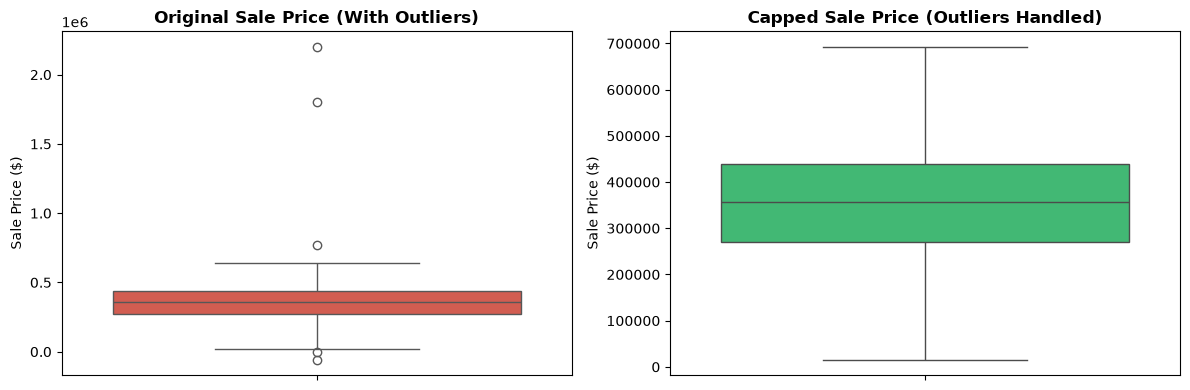

In [8]:
# Cell 8 - Task 7: Outlier Detection and Handling
# Identify Outliers using Interquartile Range (IQR) on Sale Price
Q1 = merged_df['sale_price'].quantile(0.25)
Q3 = merged_df['sale_price'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = merged_df[(merged_df['sale_price'] < lower_bound) | (merged_df['sale_price'] > upper_bound)]
print("=" * 50)
print("       OUTLIER DETECTION (SALE PRICE)")
print("=" * 50)
print(f"Q1 (25th Percentile) : ${Q1:,.2f}")
print(f"Q3 (75th Percentile) : ${Q3:,.2f}")
print(f"IQR                  : ${IQR:,.2f}")
print(f"Lower Bound          : ${lower_bound:,.2f}")
print(f"Upper Bound          : ${upper_bound:,.2f}")
print(f"Number of Outliers   : {len(outliers)}")
print("=" * 50)

# Handle Outliers: Capping (Winsorization) to upper and lower thresholds
final_cleaned_df = merged_df.copy()
final_cleaned_df['sale_price_capped'] = np.clip(final_cleaned_df['sale_price'], lower_bound, upper_bound)

# Visualize Boxplots Before and After Outlier Handling
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
sns.boxplot(y=merged_df['sale_price'], color='#e74c3c')
plt.title('Original Sale Price (With Outliers)', fontweight='bold')
plt.ylabel('Sale Price ($)')

plt.subplot(1, 2, 2)
sns.boxplot(y=final_cleaned_df['sale_price_capped'], color='#2ecc71')
plt.title('Capped Sale Price (Outliers Handled)', fontweight='bold')
plt.ylabel('Sale Price ($)')

plt.tight_layout()
plt.show()